# Diagnóstico de cancro da mama — Protótipo do agente

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

Junta as peças dos notebooks anteriores num protótipo de agente para o paciente:

1. o modelo (MobileNetV2 do notebook 01) classifica a ecografia;
2. o Grad-CAM (notebook 03) mostra onde o modelo olhou;
3. **Human-in-the-Loop:** se o modelo prevê maligno ou não tem certeza, o caso vai sempre para o médico e nada é comunicado ao paciente como resultado;
4. **Human-on-the-Loop:** os outros casos são decididos pelo sistema, mas ficam num log que o médico revê e corrige;
5. um chatbot responde às perguntas do paciente com base em documentos médicos (RAG), usando o LLM do IAedu.

Não é uma aplicação: é um protótipo para mostrar e avaliar o funcionamento.

## 1. Configuração

- `MALIGNANT_TARGET`: fração dos cancros que tem de chegar ao médico (ver secção 2).
- `CHAT_INTERACTIVE = True` abre uma conversa com `input()` na secção 5; com `False` só corre as perguntas de exemplo.
- O chatbot precisa de um ficheiro `.env` com a chave do IAedu (ver o README). Usa os documentos médicos de `docs/rag/` (as fontes estão em `docs/rag/fontes.md`). Sem `.env`, as secções 2 a 4 funcionam na mesma e a secção 5 mostra só a pesquisa nos documentos.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, MODELS_PATH, RAG_PATH, RESULTS_PATH
from src.gpu import setup_gpu

setup_gpu()

IMG_SIZE = 128
MALIGNANT_TARGET = 0.95
CHAT_INTERACTIVE = False
LOG_PATH = RESULTS_PATH / "agent_log.csv"   # fora do git

A treinar na GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Modelo e regra para chamar o médico

Um caso vai para o médico se o modelo prevê **maligno** ou se a probabilidade da classe prevista (a **confiança**) é menor do que um limiar. O notebook 03 mostrou porque a confiança não chega sozinha: o modelo falha alguns cancros com mais de 97% de certeza.

O limiar é o menor que faz chegar ao médico pelo menos `MALIGNANT_TARGET` dos cancros do conjunto de **validação** (`choose_threshold` em `src/agent.py`). Um limiar maior apanha mais cancros, mas manda mais casos ao médico. Escolhe-se na validação e não no teste, para o teste mostrar honestamente como a regra funciona em imagens novas.

In [2]:
import numpy as np
from src.agent import choose_threshold, referral_summary
from src.data import load_dataset
from src.explain import GradCAM, load_model

_, x_val, x_test, _, y_val, y_test, names_test = load_dataset(DATA_PATH, size=IMG_SIZE, test_names=True)
model = load_model(MODELS_PATH / "mobilenet.keras")
explainer = GradCAM(model)
probs_val = model.predict(x_val, verbose=0)
probs_test = model.predict(x_test, verbose=0)

threshold = choose_threshold(probs_val, y_val, MALIGNANT_TARGET)
print(f"Limiar escolhido na validação: {threshold:.2f}\n")
for name, probs, y in [("validação", probs_val, y_val), ("teste", probs_test, y_test)]:
    print(name, referral_summary(probs, y, threshold))

Limiar escolhido na validação: 0.88

validação {'enviadas ao médico': '71 de 127 (56%)', 'malignos que chegam ao médico': '36 de 37', 'erros decididos sem médico': '6 de 56'}
teste {'enviadas ao médico': '82 de 149 (55%)', 'malignos que chegam ao médico': '36 de 39', 'erros decididos sem médico': '8 de 67'}


## 3. Analisar uma ecografia

`analyse` faz o que o agente faz quando recebe uma imagem: classifica-a, calcula o Grad-CAM, decide para onde vai e mostra a mensagem para o paciente. Os exemplos são imagens do **teste** (que o modelo nunca viu): uma em que o modelo prevê maligno, uma em que não tem certeza e uma decidida sem médico.

A demonstração mostra apenas o que o paciente veria. Nos casos assinalados para revisão médica, não se mostram a previsão, a confiança nem o mapa de cores. Nos casos automáticos, a mensagem explica a confiança e o mapa é mostrado com uma explicação em linguagem simples.

Os textos para o paciente estão em `TEXTS`, em `src/agent.py`.

Olá. Este protótipo usa inteligência artificial para analisar uma imagem de ecografia da mama. Mostra uma análise automática ou assinala a imagem para revisão por um médico. É uma demonstração: não envia o exame a um médico. Quando a conversa está disponível, também pode fazer perguntas gerais sobre a ecografia.

Isto não é um diagnóstico. Fale com o seu médico para interpretar o exame e esclarecer as suas dúvidas.

Para o paciente:

O protótipo assinalou esta imagem para revisão por um médico. Por isso, não mostra a análise automática. Este aviso, por si só, não diz se há ou não um problema.

Isto não é um diagnóstico. Fale com o seu médico para interpretar o exame e esclarecer as suas dúvidas.


/home/httpirsh/Documentos/Mestrado/IACH/Projeto/.venv/lib64/python3.11/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 128, 128, 1))
  warnings.warn(msg)



Para o paciente:

O protótipo assinalou esta imagem para revisão por um médico. Por isso, não mostra a análise automática. Este aviso, por si só, não diz se há ou não um problema.

Isto não é um diagnóstico. Fale com o seu médico para interpretar o exame e esclarecer as suas dúvidas.

Para o paciente:

O programa sugeriu a categoria «benigna» para esta imagem. Esta análise automática não foi confirmada por um médico.

Confiança do modelo: 99%. A percentagem indica quão seguro o programa está da sua escolha. Não indica o seu risco de ter cancro. Mesmo com uma confiança alta, o programa pode enganar-se.

Isto não é um diagnóstico. Fale com o seu médico para interpretar o exame e esclarecer as suas dúvidas.


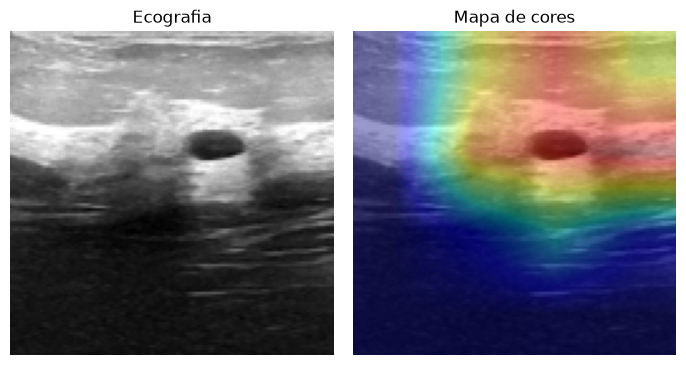


No mapa de cores, as zonas a vermelho são as que mais influenciaram a escolha do programa. As cores, por si só, não dizem se existe um problema nem onde ele está.


In [3]:
from src.agent import AUTOMATIC, TEXTS, decide, patient_message, show_case
from src.data import load_image


def analyse(file, show=True):
    image = load_image(file, IMG_SIZE)
    cam, probs = explainer(image)
    decision = decide(probs, threshold)
    if show:
        print("\nPara o paciente:\n\n" + patient_message(decision))
        if decision["encaminhamento"] == AUTOMATIC:
            show_case(image, cam, decision, patient_view=True)
            print("\n" + TEXTS["heatmap"])
    return decision


pred, conf = probs_test.argmax(axis=1), probs_test.max(axis=1)
examples = [np.where(pred == 2)[0][0],                                # prevê maligno
            np.where((pred != 2) & (conf < threshold))[0][0],         # não tem certeza
            np.where((pred != 2) & (conf >= threshold))[0][0]]        # decidido sem médico
print(TEXTS["boas_vindas"], TEXTS["aviso"], sep="\n\n")
for i in examples:
    decision = analyse(DATA_PATH / names_test[i])

## 4. Human-on-the-Loop: o log e a revisão do médico

Passam-se todas as imagens de teste pelo agente. Cada caso fica no log (`results/agent_log.csv`, fora do git) com a decisão e para onde foi. O médico revê os casos **automáticos**, isto é, os que ninguém viu, e corrige-os com `review_case`.

Aqui sabemos a classe verdadeira, por isso podemos ver quantos casos automáticos estão errados: são estes que o médico tem de apanhar na revisão.

In [4]:
from src.agent import log_case, read_log, review_case
from src.data import label_from_name

LOG_PATH.unlink(missing_ok=True)   # começar um log novo
for name, probs in zip(names_test, probs_test):   # as mesmas probabilidades da tabela da secção 2
    log_case(LOG_PATH, name, decide(probs, threshold))

log = read_log(LOG_PATH)
log["classe_real"] = log["imagem"].map(label_from_name)   # só para avaliar: o agente não a vê
automatic = log[log["encaminhamento"] == AUTOMATIC]
print(log["encaminhamento"].value_counts().to_string(), "\n")
print(f"Casos automáticos errados ({(automatic['classe_prevista'] != automatic['classe_real']).sum()}):")
automatic[automatic["classe_prevista"] != automatic["classe_real"]]

encaminhamento
médico        82
automático    67 

Casos automáticos errados (8):


,data,imagem,classe_prevista,confianca,encaminhamento,revisto,classe_medico,classe_real
19,2026-11-20T00:01:18,benign (194).png,normal,0.922,automático,False,,benign
24,2026-11-20T00:01:18,benign (212).png,normal,0.913,automático,False,,benign
50,2026-11-20T00:01:18,benign (335).png,normal,0.990,automático,False,,benign
52,2026-11-20T00:01:18,benign (344).png,normal,0.968,automático,False,,benign
53,2026-11-20T00:01:18,benign (349).png,normal,0.996,automático,False,,benign
86,2026-11-20T00:01:18,malignant (111).png,benign,0.993,automático,False,,malignant
91,2026-11-20T00:01:18,malignant (148).png,benign,0.975,automático,False,,malignant
92,2026-11-20T00:01:18,malignant (15).png,benign,0.968,automático,False,,malignant


O médico revê um caso: indica a classe correta (a mesma, se concordar). Aqui simula-se o médico com a classe verdadeira de um cancro que o sistema tinha decidido sozinho.

In [5]:
missed = automatic[(automatic["classe_real"] == "malignant") & (automatic["classe_prevista"] != "malignant")]
if len(missed):
    case = missed.iloc[0]
    print(review_case(LOG_PATH, case["imagem"], case["classe_real"]).to_string())

pending = read_log(LOG_PATH).query("encaminhamento == @AUTOMATIC and not revisto")
print(f"\nCasos automáticos ainda por rever: {len(pending)}")

                   data               imagem classe_prevista  confianca encaminhamento  revisto classe_medico
86  2026-11-20T00:01:18  malignant (111).png          benign      0.993     automático     True     malignant

Casos automáticos ainda por rever: 66


## 5. Chatbot (RAG + LLM do IAedu)

O chatbot (`src/rag.py`) procura os excertos dos documentos de `docs/rag/` mais parecidos com a pergunta e envia-os ao LLM com a pergunta e as regras: linguagem simples, citar a fonte, nunca dar um diagnóstico, sugerir falar com o médico. Também recebe o resultado do caso, exceto quando o caso foi para o médico: aí o LLM só sabe que o exame vai ser revisto, para a classe não chegar ao paciente antes de o médico a ver.

Primeiro mostra-se só a pesquisa (que excertos seriam usados), que não precisa do LLM.

In [6]:
from src.agent import case_for_chat
from src.llm import IAedu, iaedu_configured
from src.rag import Retriever, answer, load_documents

documents = load_documents(RAG_PATH)
retriever = Retriever(documents)
print(f"{len(documents)} documentos em docs/rag/, {len(retriever.chunks)} pedaços")
llm = IAedu() if iaedu_configured() else None
if llm is None:
    print("Sem .env do IAedu: mostra-se só a pesquisa nos documentos.")

questions = ["Vou ter de fazer uma biópsia?",
             "Isto quer dizer que tenho cancro?",
             "Quais são os próximos passos depois da ecografia?"]
case = case_for_chat(decide(probs_test[examples[2]], threshold))
for question in questions:
    print(f"\n### {question}")
    for name, text, score in retriever.search(question, k=3):
        print(f"  {score:.2f}  {name}: {text[:100]!r}")
    if llm is not None:
        reply, _ = answer(question, retriever, llm, case=case)
        print("\n" + reply)

19 documentos em docs/rag/, 191 pedaços

### Vou ter de fazer uma biópsia?
  0.37  chsj_biopsia_mamaria_por_agulha.md: 'A outra biópsia, que se faz só às vezes, é chamada de CITOLOGIA BIÓPSIA ASPIRATIVA (CBA), ou punção '
  0.34  chsj_biopsia_mamaria_por_agulha.md: '## As biópsias são todas iguais?\n\nNão. Há vários tipos de biópsia por agulha.\n\nA que se faz quase se'
  0.33  chsj_biopsia_mamaria_por_agulha.md: 'Há algumas lesões que precisam de biópsia e só se veem na mamografia (como é o caso das microcalcifi'



Só o médico pode decidir se você vai precisar de biópsia.

O resultado do modelo indica “benigno” com 99% de confiança, mas isso não é um diagnóstico. O modelo pode enganar-se, mesmo quando está muito confiante. A decisão deve ser revista pelo médico.

Se for necessária uma biópsia, há vários tipos. A mais comum é a **microbiópsia**, em que o médico usa uma agulha para retirar uma pequena amostra de tecido da mama. Pode ser guiada por ecografia mamária [2]. Depois, essa amostra é analisada por um patologista [4].

Algumas lesões só se veem na mamografia e, nesses casos, a biópsia pode ser feita durante a mamografia [3].

Fale com o seu médico para saber se, no seu caso, é preciso fazer biópsia.

### Isto quer dizer que tenho cancro?
  0.17  sns24_rastreio_cancro_mama.md: 'São excluídas de forma definitiva deste rastreio as pessoas que tenham feito uma mastectomia (cirurg'
  0.16  sprmn_eusobi_mamografia.md: '**Nota D.** Se for reconvocada após uma mamografia de rastreio ou se lhe for 


O resultado do modelo não quer dizer que você tem cancro.

Mas também não permite dizer, com certeza, que não tem. O modelo não faz diagnóstico. Pode enganar-se, mesmo quando está muito confiante. Só o médico pode avaliar o seu exame e, se for preciso, pedir outros exames ou uma biópsia.

Cancro, ou tumor maligno, é um crescimento anormal e descontrolado das células [4].

Se lhe for sugerida uma ecografia depois de uma mamografia, isso não quer dizer que tem cancro [2].

Fale com o seu médico para confirmar o significado do resultado no seu caso.

### Quais são os próximos passos depois da ecografia?
  0.25  chsj_mamografia_ecografia.md: '## A mamografia é um exame perfeito?\n\nNão. A mamografia tem falhas, quer por excesso quer por defeit'
  0.16  chsj_mamografia_ecografia.md: '# Mamografia e ecografia mamária: recomendações ao doente\n\nFonte: Centro de Mama do Centro Hospitala'
  0.16  chsj_biopsia_mamaria_por_agulha.md: 'A biópsia é feita com uma agulha muito fina, como um alfinet


Os próximos passos devem ser definidos pelo médico que revê a sua ecografia.

O resultado do modelo diz “benigno” com 99% de confiança, mas não é um diagnóstico. O médico pode rever o exame e decidir se é preciso fazer mais alguma coisa.

Depois de uma ecografia mamária, o médico pode:

- rever o resultado da ecografia;
- comparar com outros exames, como a mamografia, se existirem;
- pedir outros exames, se achar necessário. A mamografia é uma radiografia da mama e pode ser usada para rastreio ou avaliação [2];
- indicar uma biópsia, se houver um nódulo ou alteração que precise de ser analisada. Muitas biópsias por agulha são feitas com orientação por ecografia, para o médico ver a agulha a chegar ao local certo [3].

A ecografia mamária é um exame de imagem feito às mamas com ultrassons [1].

Fale com o seu médico para saber qual é o próximo passo no seu caso.


Perguntas de teste (`docs/rag/perguntas_teste.csv`, issue #8): para cada pergunta normal, verifica-se se o documento que a responde está entre os 4 excertos enviados ao LLM. As perguntas com `deve_recusar = sim` (pedidos de diagnóstico, medicamentos, conselhos pessoais, fora do tema) não entram aqui: nelas o chatbot tem de recusar, e isso avalia-se nas respostas do LLM (#9).

In [7]:
import pandas as pd

tests = pd.read_csv(RAG_PATH / "perguntas_teste.csv")
normal = tests[tests["deve_recusar"] == "nao"]
hits = 0
for _, row in normal.iterrows():
    expected = {f.strip() + ".md" for f in row["documento_fonte"].split(";")}
    found = [name for name, _, _ in retriever.search(row["pergunta"])]   # os 4 excertos que o LLM recebe
    hits += bool(expected & set(found))
    if not expected & set(found):
        print(f"falhou {row['id']}: {row['pergunta']} -> {found}")
print(f"\n{hits} de {len(normal)} perguntas com o documento esperado nos 4 excertos")

falhou 1: O que quer dizer um resultado benigno? -> ['sns24_rastreio_cancro_mama.md', 'sprmn_eusobi_mamografia.md', 'sns24_mamografia.md', 'sns24_rastreio_cancro_mama.md']
falhou 14: Uma pancada na mama pode causar cancro? -> ['lpcc_cancro_da_mama.md', 'lpcc_cancro_da_mama.md', 'sns24_cancro_o_que_e.md', 'dgs_perguntas_respostas_cancro.md']
falhou 24: Quais são os próximos passos depois da ecografia? -> ['chsj_mamografia_ecografia.md', 'chsj_mamografia_ecografia.md', 'chsj_biopsia_mamaria_por_agulha.md', 'lpcc_deteccao.md']

21 de 24 perguntas com o documento esperado nos 4 excertos


Avaliação das respostas (issue #9): as 30 perguntas de teste são enviadas ao LLM, cada uma numa conversa nova e com o mesmo caso da conversa acima (decidido sem médico, o caso em que há mais risco de falsa tranquilização). As respostas ficam em `results/avaliacao_chatbot.csv`, com:

- `fontes_usadas`: os 4 excertos enviados ao LLM; `documento_encontrado`: se o documento esperado está entre eles;
- `cita_fonte`: se a resposta tem uma citação como [1] (verificação automática);
- `avaliacao` (correta / parcial / errada), `recusa_correta` (sim / não, nas perguntas com `deve_recusar = sim`) e `notas`: vazias, para preencher à mão comparando com `resposta_esperada`.

O ficheiro é gravado a cada resposta. Se o IAedu parar (por exemplo, por limite de pedidos), voltar a correr a célula continua a partir da pergunta onde parou. Para refazer tudo, apagar o ficheiro.

As respostas com a primeira versão das regras do chatbot (antes das regras sobre responder primeiro à pergunta, não chamar tranquilizador ao resultado e mandar ao médico os sintomas descritos) estão em `results/avaliacao_chatbot_regras_v1.csv`, já classificadas.

In [8]:
import re
import time

EVAL_PATH = RESULTS_PATH / "avaliacao_chatbot.csv"
MANUAL = ["avaliacao", "recusa_correta", "notas"]   # preenchidas à mão

rows = pd.read_csv(EVAL_PATH).to_dict("records") if EVAL_PATH.exists() else []
answered = {row["id"] for row in rows}
if llm is None:
    print("Sem .env do IAedu: não é possível avaliar as respostas.")
else:
    for _, row in tests[~tests["id"].isin(answered)].iterrows():
        llm.new_conversation()   # cada pergunta numa conversa nova, para não depender das anteriores
        try:
            reply, passages = answer(row["pergunta"], retriever, llm, case=case)
        except RuntimeError as error:
            print(f"Parou na pergunta {row['id']} ({error}). Voltar a correr a célula para continuar.")
            break
        used = [name.removesuffix(".md") for name, _, _ in passages]
        expected = {f.strip() for f in str(row["documento_fonte"]).split(";")} if pd.notna(row["documento_fonte"]) else set()
        rows.append({**row, "resposta": reply, "fontes_usadas": "; ".join(used),
                     "documento_encontrado": bool(expected & set(used)) if expected else None,
                     "cita_fonte": bool(re.search(r"\[\d+\]", reply)), **{c: "" for c in MANUAL}})
        pd.DataFrame(rows).to_csv(EVAL_PATH, index=False)
        time.sleep(2)   # não fazer os pedidos todos seguidos

evaluation = pd.DataFrame(rows)
print(f"{len(evaluation)} de {len(tests)} perguntas respondidas ({EVAL_PATH.relative_to(ROOT)})")
if len(evaluation):
    print(f"Respostas com citação: {evaluation['cita_fonte'].sum()} de {len(evaluation)}")
    print(evaluation.groupby("deve_recusar")["cita_fonte"].agg(["sum", "count"]).to_string())


30 de 30 perguntas respondidas (results/avaliacao_chatbot.csv)
Respostas com citação: 30 de 30
              sum  count
deve_recusar            
nao            24     24
sim             6      6


Conversa livre (com `CHAT_INTERACTIVE = True`). Escrever `sair` para terminar.

In [9]:
if CHAT_INTERACTIVE and llm is not None:
    llm.new_conversation()
    print(TEXTS["boas_vindas"], "\n" + TEXTS["aviso"])
    while (question := input("Pergunta: ").strip()).lower() not in ("sair", ""):
        reply, passages = answer(question, retriever, llm, case=case)
        print(reply, "\n   fontes:", sorted({name for name, _, _ in passages}))

## 6. Estado

- Feito: classificação, Grad-CAM, regra para chamar o médico escolhida na validação, log e revisão do médico, documentos médicos (19, em `docs/rag/`), pesquisa nos documentos, perguntas de teste (30, em `docs/rag/perguntas_teste.csv`), ligação ao LLM do IAedu e avaliação das respostas do chatbot com duas versões das regras (`results/avaliacao_chatbot_regras_v1.csv` e `results/avaliacao_chatbot.csv`).
- Feito: mensagens para o paciente (#10), com aviso de não diagnóstico e explicações em linguagem simples da confiança e do mapa de cores.